In [ ]:
import os
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                              recall_score, f1_score, confusion_matrix,
                              roc_curve, ConfusionMatrixDisplay)

In [ ]:
SEED = 11
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


In [ ]:
df = pd.read_csv('early_2012_2013_loan_sample_with_outcome.csv')

In [ ]:
# Data Cleaning
df['revol_util'] = pd.to_numeric(
    df['revol_util'].astype(str).str.rstrip('%'), errors='coerce'
)

# Engineer credit age from earliest_cr_line
MONTH_MAP = {m: i + 1 for i, m in enumerate(
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)}

def credit_age_months(d, ref_year=2013):
    """Months of credit history relative to 2013."""
    if pd.isna(d):
        return np.nan
    try:
        m, y = d.split('-')
        return (ref_year - int(y)) * 12 - MONTH_MAP[m]
    except Exception:
        return np.nan

df['credit_age_months'] = df['earliest_cr_line'].apply(credit_age_months)

In [ ]:
NUMERIC_FEATURES = [
    'funded_amnt',
    'term', 'int_rate',
    'emp_length', 'annual_inc', 'dti',
    'delinq_2yrs', 'inq_last_6mths',
    'mths_since_last_delinq', 'mths_since_last_record',
    'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
    'collections_12_mths_ex_med', 'mths_since_last_major_derog',
    'acc_now_delinq',
    'tot_coll_amt', 'tot_cur_bal', 'total_credit_rv',
    'credit_age_months'
]

CATEGORICAL_FEATURES = [
    'sub_grade',
    'home_ownership', 'verification_status',
    'purpose', 'addr_state', 'initial_list_status'
]

TARGET      = 'loan_is_bad'
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

In [ ]:
def parse_issue_date(d):
    if pd.isna(d):
        return 0
    m, y = d.split('-')
    return int(y) * 100 + MONTH_MAP[m]

df['issue_d_num'] = df['issue_d'].apply(parse_issue_date)
df_sorted = df.sort_values('issue_d_num').reset_index(drop=True)

n         = len(df_sorted)
train_end = int(n * 0.60)
val_end   = int(n * 0.80)

train_df = df_sorted.iloc[:train_end].copy()
val_df   = df_sorted.iloc[train_end:val_end].copy()
test_df  = df_sorted.iloc[val_end:].copy()

print("\nDATA SPLIT SUMMARY")
for name, d in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    pos   = d[TARGET].sum()
    pct   = 100 * pos / len(d)
    dates = sorted(d['issue_d'].dropna().unique(), key=parse_issue_date)
    print(f"{name:12s}: n={len(d):6d} | defaults={pos:5d} ({pct:.1f}%) "
          f"| {dates[0]} → {dates[-1]}")


DATA SPLIT SUMMARY
Train       : n= 30000 | defaults= 4820 (16.1%) | May-2012 → Nov-2012
Validation  : n= 10000 | defaults= 1543 (15.4%) | Nov-2012 → Dec-2012
Test        : n= 10000 | defaults= 1451 (14.5%) | Dec-2012 → Feb-2013


In [ ]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe',     OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, NUMERIC_FEATURES),
    ('cat', cat_pipeline, CATEGORICAL_FEATURES)
], remainder='drop')

X_train_np = preprocessor.fit_transform(train_df[ALL_FEATURES])
X_val_np   = preprocessor.transform(val_df[ALL_FEATURES])
X_test_np  = preprocessor.transform(test_df[ALL_FEATURES])

y_train_np = train_df[TARGET].astype(int).values
y_val_np   = val_df[TARGET].astype(int).values
y_test_np  = test_df[TARGET].astype(int).values

INPUT_DIM = X_train_np.shape[1]
print(f"\nInput dimension after preprocessing: {INPUT_DIM}")
print(f"  Numeric features : {len(NUMERIC_FEATURES)}")
print(f"  OHE categories   : {INPUT_DIM - len(NUMERIC_FEATURES)}")


Input dimension after preprocessing: 122
  Numeric features : 22
  OHE categories   : 100


In [ ]:
neg_count  = (y_train_np == 0).sum()
pos_count  = (y_train_np == 1).sum()
POS_WEIGHT = neg_count / pos_count

print(f"\nClass distribution — negative: {neg_count}, positive: {pos_count}")
print(f"pos_weight = {POS_WEIGHT:.2f}  (upweights default class in loss)")


Class distribution — negative: 25180, positive: 4820
pos_weight = 5.22  (upweights default class in loss)


In [ ]:
def to_tensor(X, y):
    return (
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.float32).unsqueeze(1)
    )

X_train_t, y_train_t = to_tensor(X_train_np, y_train_np)
X_val_t,   y_val_t   = to_tensor(X_val_np,   y_val_np)
X_test_t,  y_test_t  = to_tensor(X_test_np,  y_test_np)

BATCH_SIZE   = 512
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t),
                          batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_t, y_val_t),
                          batch_size=BATCH_SIZE, shuffle=False)

In [ ]:
class LoanDefaultMLP(nn.Module):
    """
    Feedforward MLP for binary credit default prediction.
    Architecture: 256 → 128 → 64 → 32 with BatchNorm + ReLU + Dropout.
    """
    def __init__(self, input_dim: int, dropout_p: float = 0.2):
        super().__init__()
        self.network = nn.Sequential(
            # Block 1
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            # Block 2
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            # Block 3
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            # Block 4
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(p=0.1),
            # Output — no sigmoid (BCEWithLogitsLoss handles it)
            nn.Linear(32, 1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.network(x)


model = LoanDefaultMLP(input_dim=INPUT_DIM).to(DEVICE)
print("\nMODEL ARCHITECTURE")
print(model)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTrainable parameters: {total_params:,}")



MODEL ARCHITECTURE
LoanDefaultMLP(
  (network): Sequential(
    (0): Linear(in_features=122, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=64, out_features=32, bias=True)
    (13): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
    (15): Dropout(p=0.1, inplace=False)
    (16): Linear(in_features=32, out_features=1, bias=True)
  )
)

Trainable parameters: 75,713


In [ ]:
pos_weight_tensor = torch.tensor([POS_WEIGHT], dtype=torch.float32).to(DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)

optimizer = optim.Adam(model.parameters(), lr=5e-5, weight_decay=1e-4)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=10
)

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss   = criterion(logits, y_batch)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * X_batch.size(0)
    return total_loss / len(loader.dataset)

def evaluate_loss(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)
            loss   = criterion(logits, y_batch)
            total_loss += loss.item() * X_batch.size(0)
    return total_loss / len(loader.dataset)

def compute_auc(model, loader, device):
    model.eval()
    all_logits, all_labels = [], []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            logits  = model(X_batch)
            all_logits.append(logits.cpu().numpy())
            all_labels.append(y_batch.numpy())
    logits_arr = np.concatenate(all_logits).ravel()
    labels_arr = np.concatenate(all_labels).ravel()
    probs      = 1 / (1 + np.exp(-logits_arr))
    return roc_auc_score(labels_arr, probs)


MAX_EPOCHS          = 200
EARLY_STOP_PATIENCE = 30

best_val_auc      = 0.0
best_state_dict   = None
epochs_no_improve = 0
history = {'train_loss': [], 'val_loss': [], 'val_auc': []}

print("\nTRAINING")
for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE)
    val_loss   = evaluate_loss(model, val_loader, criterion, DEVICE)
    val_auc    = compute_auc(model, val_loader, DEVICE)
    scheduler.step(val_loss)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_auc'].append(val_auc)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d} | TrainLoss={train_loss:.4f} | "
              f"ValLoss={val_loss:.4f} | ValAUC={val_auc:.4f}")

    if val_auc > best_val_auc:
        best_val_auc      = val_auc
        best_state_dict   = {k: v.clone() for k, v in model.state_dict().items()}
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= EARLY_STOP_PATIENCE:
            print(f"\nEarly stopping at epoch {epoch} "
                  f"(no improvement for {EARLY_STOP_PATIENCE} epochs).")
            break

model.load_state_dict(best_state_dict)
print(f"\nBest validation AUC: {best_val_auc:.4f}")
torch.save({'model_state': model.state_dict(), 'input_dim': INPUT_DIM},
           'loan_default_mlp.pt')


TRAINING
Epoch   1 | TrainLoss=1.1985 | ValLoss=1.1650 | ValAUC=0.5895
Epoch   5 | TrainLoss=1.1348 | ValLoss=1.1107 | ValAUC=0.6494
Epoch  10 | TrainLoss=1.1062 | ValLoss=1.0930 | ValAUC=0.6543
Epoch  15 | TrainLoss=1.0956 | ValLoss=1.0856 | ValAUC=0.6564
Epoch  20 | TrainLoss=1.0905 | ValLoss=1.0824 | ValAUC=0.6581
Epoch  25 | TrainLoss=1.0840 | ValLoss=1.0816 | ValAUC=0.6591
Epoch  30 | TrainLoss=1.0770 | ValLoss=1.0821 | ValAUC=0.6596
Epoch  35 | TrainLoss=1.0734 | ValLoss=1.0823 | ValAUC=0.6603
Epoch  40 | TrainLoss=1.0720 | ValLoss=1.0828 | ValAUC=0.6603
Epoch  45 | TrainLoss=1.0646 | ValLoss=1.0846 | ValAUC=0.6600
Epoch  50 | TrainLoss=1.0614 | ValLoss=1.0849 | ValAUC=0.6603
Epoch  55 | TrainLoss=1.0626 | ValLoss=1.0859 | ValAUC=0.6602
Epoch  60 | TrainLoss=1.0572 | ValLoss=1.0857 | ValAUC=0.6606
Epoch  65 | TrainLoss=1.0607 | ValLoss=1.0859 | ValAUC=0.6605

Early stopping at epoch 66 (no improvement for 30 epochs).

Best validation AUC: 0.6608


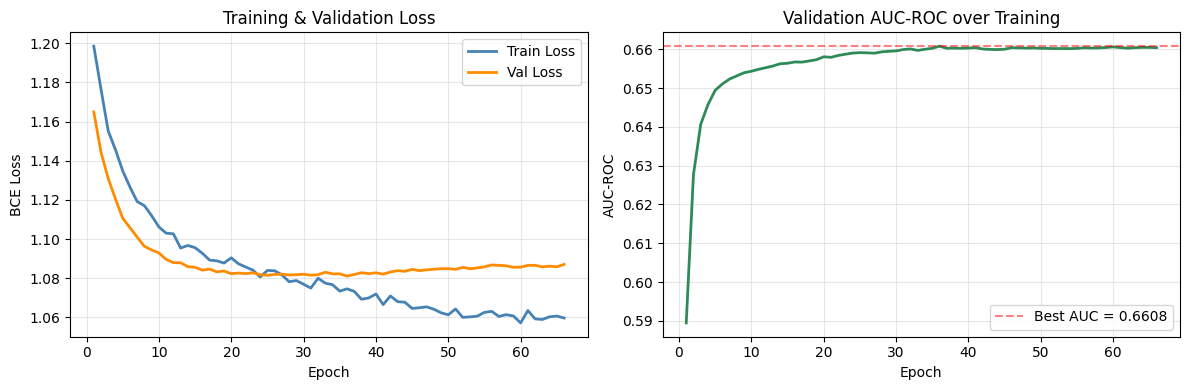

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
epochs_range = range(1, len(history['train_loss']) + 1)

ax1.plot(epochs_range, history['train_loss'], label='Train Loss',
         color='steelblue', linewidth=2)
ax1.plot(epochs_range, history['val_loss'], label='Val Loss',
         color='darkorange', linewidth=2)
ax1.set_xlabel('Epoch')
ax1.set_ylabel('BCE Loss')
ax1.set_title('Training & Validation Loss')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(epochs_range, history['val_auc'], color='seagreen', linewidth=2)
ax2.set_xlabel('Epoch')
ax2.set_ylabel('AUC-ROC')
ax2.set_title('Validation AUC-ROC over Training')
ax2.axhline(y=best_val_auc, color='red', linestyle='--', alpha=0.5,
            label=f'Best AUC = {best_val_auc:.4f}')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('q3_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
def get_predictions(model, X_np, device, threshold=0.5):
    model.eval()
    X_t = torch.tensor(X_np, dtype=torch.float32).to(device)
    with torch.no_grad():
        logits = model(X_t).cpu().numpy().ravel()
    probs = 1 / (1 + np.exp(-logits))
    preds = (probs >= threshold).astype(int)
    return probs, preds

def evaluate_full(name, y_true, probs, preds):
    auc  = roc_auc_score(y_true, probs)
    acc  = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds, zero_division=0)
    rec  = recall_score(y_true, preds, zero_division=0)
    f1   = f1_score(y_true, preds, zero_division=0)
    cm   = confusion_matrix(y_true, preds)
    print(f"\nPERFORMANCE METRICS — {name.upper()}")
    print(f"  AUC-ROC   : {auc:.4f}")
    print(f"  Accuracy  : {acc:.4f}")
    print(f"  Precision : {prec:.4f}")
    print(f"  Recall    : {rec:.4f}")
    print(f"  F1-Score  : {f1:.4f}")
    print(f"\n  Confusion Matrix (rows=actual, cols=predicted):")
    print(f"  TN={cm[0,0]:5d}  FP={cm[0,1]:5d}")
    print(f"  FN={cm[1,0]:5d}  TP={cm[1,1]:5d}")
    return {'auc': auc, 'acc': acc, 'prec': prec,
            'rec': rec, 'f1': f1, 'cm': cm}


# -- Cost-weighted threshold tuning on validation set --
val_probs_raw, _ = get_predictions(model, X_val_np, DEVICE)
thresholds       = np.arange(0.05, 0.95, 0.01)

# FN costs 5x more than FP — reflects asymmetric cost of missing a default
FN_COST = 5
FP_COST = 1

best_t, best_cost = 0.5, float('inf')
for t in thresholds:
    preds_t = (val_probs_raw >= t).astype(int)
    cm_t    = confusion_matrix(y_val_np, preds_t)
    cost    = FN_COST * cm_t[1, 0] + FP_COST * cm_t[0, 1]
    if cost < best_cost:
        best_cost, best_t = cost, t

print(f"Cost-optimal threshold: {best_t:.2f}  |  Total cost: {best_cost}")

# -- Final predictions with tuned threshold --
val_probs,  val_preds  = get_predictions(model, X_val_np,  DEVICE, threshold=best_t)
test_probs, test_preds = get_predictions(model, X_test_np, DEVICE, threshold=best_t)

val_metrics  = evaluate_full('Validation', y_val_np,  val_probs,  val_preds)
test_metrics = evaluate_full('Test',       y_test_np, test_probs, test_preds)

Cost-optimal threshold: 0.53  |  Total cost: 6161

PERFORMANCE METRICS — VALIDATION
  AUC-ROC   : 0.6608
  Accuracy  : 0.6319
  Precision : 0.2317
  Recall    : 0.5982
  F1-Score  : 0.3340

  Confusion Matrix (rows=actual, cols=predicted):
  TN= 5396  FP= 3061
  FN=  620  TP=  923

PERFORMANCE METRICS — TEST
  AUC-ROC   : 0.6614
  Accuracy  : 0.6327
  Precision : 0.2206
  Recall    : 0.6044
  F1-Score  : 0.3232

  Confusion Matrix (rows=actual, cols=predicted):
  TN= 5450  FP= 3099
  FN=  574  TP=  877


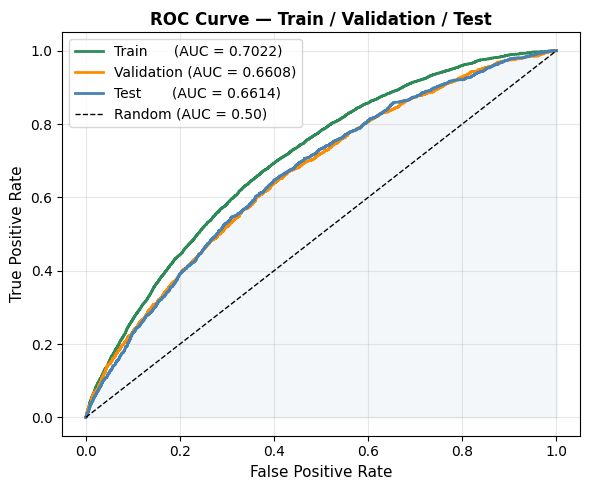

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))

# Compute ROC for all three sets
train_probs_raw, _ = get_predictions(model, X_train_np, DEVICE)
val_probs_raw2, _  = get_predictions(model, X_val_np,   DEVICE)

fpr_train, tpr_train, _ = roc_curve(y_train_np, train_probs_raw)
fpr_val,   tpr_val,   _ = roc_curve(y_val_np,   val_probs_raw2)
fpr_test,  tpr_test,  _ = roc_curve(y_test_np,  test_probs)

auc_train = roc_auc_score(y_train_np, train_probs_raw)
auc_val   = roc_auc_score(y_val_np,   val_probs_raw2)
auc_test  = test_metrics['auc']

ax.plot(fpr_train, tpr_train, color='seagreen',   lw=2,
        label=f"Train      (AUC = {auc_train:.4f})")
ax.plot(fpr_val,   tpr_val,   color='darkorange',  lw=2,
        label=f"Validation (AUC = {auc_val:.4f})")
ax.plot(fpr_test,  tpr_test,  color='steelblue',   lw=2,
        label=f"Test       (AUC = {auc_test:.4f})")
ax.fill_between(fpr_test, tpr_test, alpha=0.06, color='steelblue')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC = 0.50)')

ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate', fontsize=11)
ax.set_title('ROC Curve — Train / Validation / Test', fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('q3_roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

Figure 3 saved: q3_confusion_matrix.png


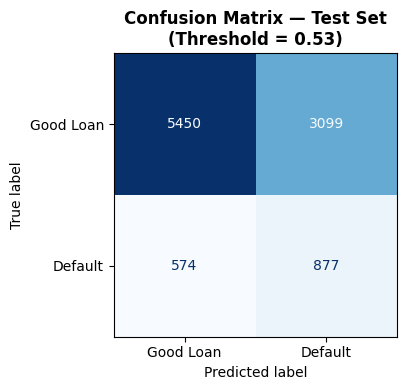

In [ ]:
fig, ax = plt.subplots(figsize=(5, 4))
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=test_metrics['cm'],
    display_labels=['Good Loan', 'Default']
)
cm_display.plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title(f'Confusion Matrix — Test Set\n(Threshold = {best_t:.2f})',
             fontweight='bold')
plt.tight_layout()
plt.savefig('q3_confusion_matrix.png', dpi=150, bbox_inches='tight')
print("Figure 3 saved: q3_confusion_matrix.png")
plt.show()


THRESHOLD SENSITIVITY — Test Set
 Threshold | Approved | Approval% |  Recall | Precision |      F1
-----------------------------------------------------------------
      0.20 |      924 |      9.2% |   0.974 |     0.156 |   0.268
      0.25 |     1430 |     14.3% |   0.943 |     0.160 |   0.273
      0.30 |     2039 |     20.4% |   0.917 |     0.167 |   0.283
      0.35 |     2673 |     26.7% |   0.879 |     0.174 |   0.290
      0.40 |     3338 |     33.4% |   0.837 |     0.182 |   0.299
      0.50 |     5258 |     52.6% |   0.677 |     0.207 |   0.317
      0.53 |     6024 |     60.2% |   0.604 |     0.221 |   0.323 ← selected

Figure 4 saved: q3_threshold_sensitivity.png


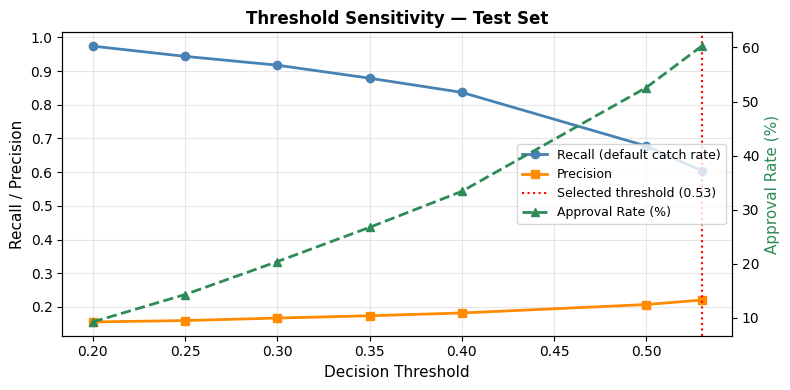

In [ ]:
print("\nTHRESHOLD SENSITIVITY — Test Set")
print(f"{'Threshold':>10} | {'Approved':>8} | {'Approval%':>9} | "
      f"{'Recall':>7} | {'Precision':>9} | {'F1':>7}")
print("-" * 65)

thresh_results = []
for thresh in [0.20, 0.25, 0.30, 0.35, 0.40, 0.50, 0.53]:
    preds_t    = (test_probs >= thresh).astype(int)
    n_approved = len(preds_t) - preds_t.sum()
    rec        = recall_score(y_test_np, preds_t, zero_division=0)
    prec       = precision_score(y_test_np, preds_t, zero_division=0)
    f1_        = f1_score(y_test_np, preds_t, zero_division=0)
    appr_pct   = 100 * n_approved / len(preds_t)
    thresh_results.append({
        'threshold': thresh, 'approval_pct': appr_pct,
        'recall': rec, 'precision': prec
    })
    marker = " ← selected" if abs(thresh - best_t) < 0.005 else ""
    print(f"  {thresh:>8.2f} | {n_approved:>8d} | {appr_pct:>8.1f}% | "
          f"{rec:>7.3f} | {prec:>9.3f} | {f1_:>7.3f}{marker}")

# Chart 4: Threshold sensitivity
thresh_df = pd.DataFrame(thresh_results)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax2 = ax1.twinx()

ax1.plot(thresh_df['threshold'], thresh_df['recall'],
         color='steelblue', marker='o', linewidth=2, label='Recall (default catch rate)')
ax1.plot(thresh_df['threshold'], thresh_df['precision'],
         color='darkorange', marker='s', linewidth=2, label='Precision')
ax2.plot(thresh_df['threshold'], thresh_df['approval_pct'],
         color='seagreen', marker='^', linewidth=2, linestyle='--',
         label='Approval Rate (%)')

ax1.axvline(x=best_t, color='red', linestyle=':', linewidth=1.5,
            label=f'Selected threshold ({best_t:.2f})')
ax1.set_xlabel('Decision Threshold', fontsize=11)
ax1.set_ylabel('Recall / Precision', fontsize=11)
ax2.set_ylabel('Approval Rate (%)', fontsize=11, color='seagreen')
ax1.set_title('Threshold Sensitivity — Test Set', fontweight='bold')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, fontsize=9, loc='center right')
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('q3_threshold_sensitivity.png', dpi=150, bbox_inches='tight')
print("\nFigure 4 saved: q3_threshold_sensitivity.png")
plt.show()

CLUSTER-LEVEL AUC-ROC (Q2 cluster labels)

  Cluster Label                                    n  Default%     AUC
  --------------------------------------------------------------------
  1      Highest-cost / Weakest Credit         1786   20.38%  0.6255
  2      Mainstream / Lower-risk               5410   11.59%  0.6377
  3      Delinquency-history                   1095   13.42%  0.6694
  4      High-inquiry / Active Credit          1507   18.12%  0.6426


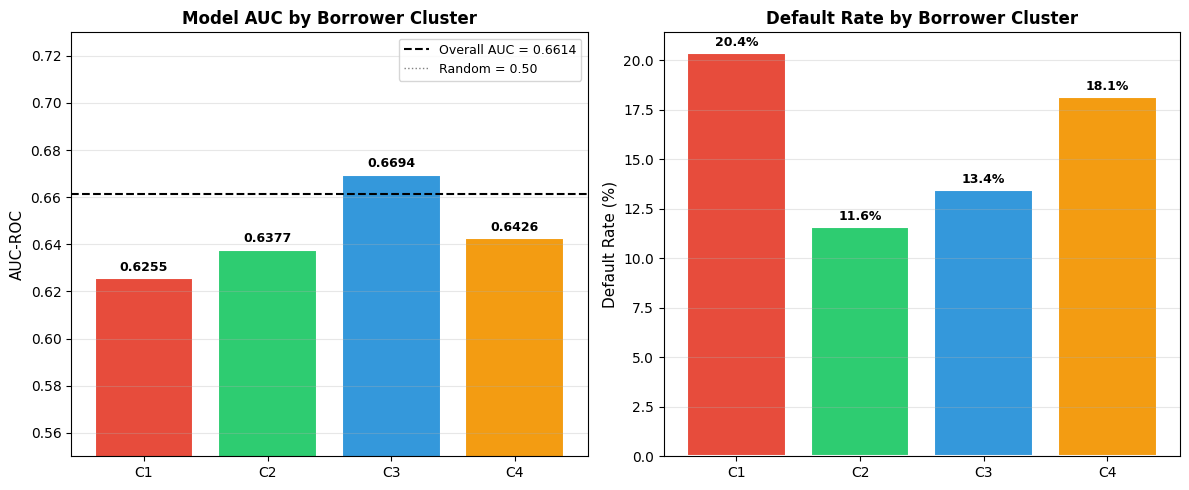

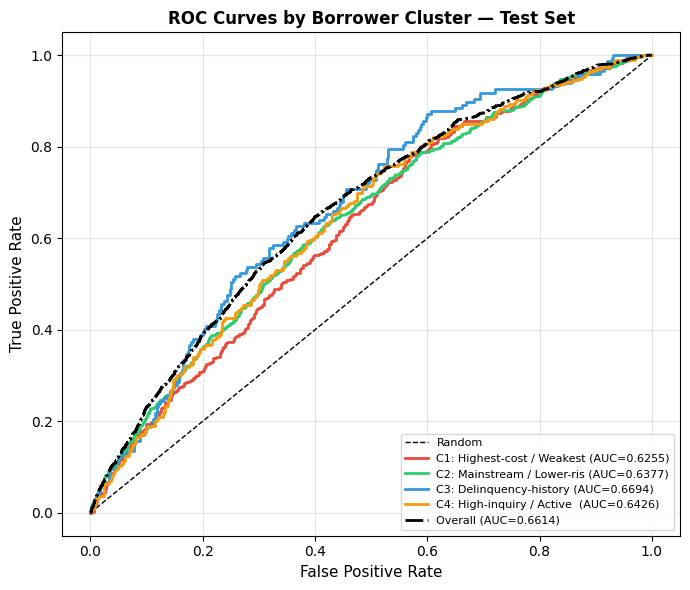

In [ ]:
cluster_label_path = 'cluster_labels.csv'

CLUSTER_NAMES = {
    1: "Highest-cost / Weakest Credit",
    2: "Mainstream / Lower-risk",
    3: "Delinquency-history",
    4: "High-inquiry / Active Credit"
}

if os.path.exists(cluster_label_path):
    cluster_df = pd.read_csv(cluster_label_path)

    test_df_eval           = test_df.copy()
    test_df_eval['prob']   = test_probs
    test_df_eval['y_true'] = y_test_np
    test_df_eval           = test_df_eval.merge(cluster_df, on='member_id', how='left')

    n_matched   = test_df_eval['cluster'].notna().sum()
    n_unmatched = test_df_eval['cluster'].isna().sum()

    print("CLUSTER-LEVEL AUC-ROC (Q2 cluster labels)\n")
    print(f"  {'Cluster':<6} {'Label':<35} {'n':>6} {'Default%':>9} {'AUC':>7}")
    print("  " + "-" * 68)

    cluster_rows   = test_df_eval.dropna(subset=['cluster'])
    cluster_aucs   = {}
    cluster_sizes  = {}
    cluster_defrates = {}

    for c in sorted(cluster_rows['cluster'].unique()):
        subset = cluster_rows[cluster_rows['cluster'] == c]
        if subset['y_true'].nunique() < 2 or len(subset) < 30:
            continue
        c_auc  = roc_auc_score(subset['y_true'], subset['prob'])
        c_def  = subset['y_true'].mean()
        label  = CLUSTER_NAMES.get(int(c), f"Cluster {int(c)}")
        cluster_aucs[int(c)]     = c_auc
        cluster_sizes[int(c)]    = len(subset)
        cluster_defrates[int(c)] = c_def
        print(f"  {int(c):<6} {label:<35} {len(subset):>6} "
              f"{c_def:>8.2%} {c_auc:>7.4f}")

    # Chart 5: Per-cluster AUC bar chart
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    clusters  = list(cluster_aucs.keys())
    aucs      = [cluster_aucs[c] for c in clusters]
    def_rates = [cluster_defrates[c] * 100 for c in clusters]
    labels    = labels = [f"C{c}" for c in clusters]
    colors    = ['#e74c3c', '#2ecc71', '#3498db', '#f39c12']

    # AUC by cluster
    bars = axes[0].bar(labels, aucs, color=colors, edgecolor='white', linewidth=1.5)
    axes[0].axhline(y=test_metrics['auc'], color='black', linestyle='--',
                    linewidth=1.5, label=f"Overall AUC = {test_metrics['auc']:.4f}")
    axes[0].axhline(y=0.5, color='grey', linestyle=':', linewidth=1,
                    label='Random = 0.50')
    for bar, auc in zip(bars, aucs):
        axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.002,
                     f'{auc:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    axes[0].set_ylim(0.55, 0.73)
    axes[0].set_ylabel('AUC-ROC', fontsize=11)
    axes[0].set_title('Model AUC by Borrower Cluster', fontweight='bold')
    axes[0].legend(fontsize=9)
    axes[0].grid(axis='y', alpha=0.3)

    # Default rate by cluster
    bars2 = axes[1].bar(labels, def_rates, color=colors, edgecolor='white', linewidth=1.5)
    for bar, dr in zip(bars2, def_rates):
        axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.2,
                     f'{dr:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
    axes[1].set_ylabel('Default Rate (%)', fontsize=11)
    axes[1].set_title('Default Rate by Borrower Cluster', fontweight='bold')
    axes[1].grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.savefig('q3_cluster_performance.png', dpi=150, bbox_inches='tight')
    plt.show()

    # Chart 6: Per-cluster ROC curves
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')

    for c, colour in zip(sorted(cluster_aucs.keys()), colors):
        subset = cluster_rows[cluster_rows['cluster'] == c]
        fpr_c, tpr_c, _ = roc_curve(subset['y_true'], subset['prob'])
        ax.plot(fpr_c, tpr_c, color=colour, lw=2,
                label=f"C{c}: {CLUSTER_NAMES[c][:22]} (AUC={cluster_aucs[c]:.4f})")

    fpr_all, tpr_all, _ = roc_curve(y_test_np, test_probs)
    ax.plot(fpr_all, tpr_all, color='black', lw=2, linestyle='-.',
            label=f"Overall (AUC={test_metrics['auc']:.4f})")

    ax.set_xlabel('False Positive Rate', fontsize=11)
    ax.set_ylabel('True Positive Rate', fontsize=11)
    ax.set_title('ROC Curves by Borrower Cluster — Test Set', fontweight='bold')
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig('q3_cluster_roc_curves.png', dpi=150, bbox_inches='tight')
    plt.show()

else:
    print("\nWARNING: cluster_labels.csv not found.")
    print("Run the Q2 R export block first, then re-run this section.")
    print("Falling back to grade as proxy:\n")

    test_df_eval           = test_df.copy()
    test_df_eval['prob']   = test_probs
    test_df_eval['y_true'] = y_test_np

    for grade in sorted(test_df_eval['grade'].dropna().unique()):
        mask   = test_df_eval['grade'] == grade
        subset = test_df_eval[mask]
        if subset['y_true'].nunique() < 2 or len(subset) < 50:
            continue
        g_auc = roc_auc_score(subset['y_true'], subset['prob'])
        g_def = subset['y_true'].mean()
        print(f"  Grade {grade}: n={len(subset):5d} | "
              f"default_rate={g_def:.2%} | AUC={g_auc:.4f}")


Figure 7 saved: q3_score_distribution.png


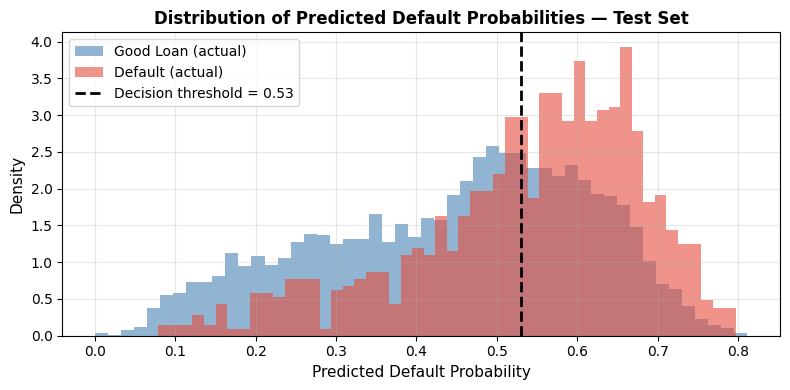

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(test_probs[y_test_np == 0], bins=50, alpha=0.6,
        color='steelblue', label='Good Loan (actual)', density=True)
ax.hist(test_probs[y_test_np == 1], bins=50, alpha=0.6,
        color='#e74c3c', label='Default (actual)', density=True)
ax.axvline(x=best_t, color='black', linestyle='--', linewidth=2,
           label=f'Decision threshold = {best_t:.2f}')
ax.set_xlabel('Predicted Default Probability', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.set_title('Distribution of Predicted Default Probabilities — Test Set',
             fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('q3_score_distribution.png', dpi=150, bbox_inches='tight')
plt.show()